In [6]:
# Импорты и загрузка данных

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

files = {
    'chelyabinsk': '75_chelyabinsk.csv',
    'kurgan': '37_kurgan.csv',
    'tumen': '71_tumen.csv',
}

date_col = 'date'
target = 'actual_consumption'
region_frames = []

for region_name, filepath in files.items():
  d = pd.read_csv(filepath)
  d = d.loc[:, ~d.columns.str.startswith('Unnamed:')]
  d[date_col] = pd.to_datetime(d[date_col])
  d = (
      d.sort_values(date_col)
      .drop_duplicates(subset=[date_col])
      .set_index(date_col)
  )

  # Регулярная почасовая сетка внутри конкретного региона
  full_idx = pd.date_range(start=d.index.min(), end=d.index.max(), freq='h')
  d = d.reindex(full_idx)
  d.index.name = date_col
  d['region'] = region_name

  d = d[d[target].notna() & (d[target] > 0)].copy()

  # Календарные признаки
  d['hour'] = d.index.hour
  d['dayofweek'] = d.index.dayofweek
  d['is_weekend'] = (d['dayofweek'] >= 5).astype(int)
  d['month'] = d.index.month

  # Лаги и скользящие статистики строго в рамках одного региона
  d['lag_1'] = d[target].shift(1)
  d['lag_24'] = d[target].shift(24)
  d['lag_168'] = d[target].shift(168)
  d['rolling_mean_24'] = d[target].shift(1).rolling(24).mean()
  d['rolling_std_24'] = d[target].shift(1).rolling(24).std()
  d['plan_minus_lag24'] = d['planned_consumption'] - d['lag_24']

  region_frames.append(d)

df = pd.concat(region_frames).sort_index()
df['region_code'] = df['region'].astype('category').cat.codes

features = [
    'region_code',
    'hour',
    'dayofweek',
    'is_weekend',
    'month',
    'lag_1',
    'lag_24',
    'lag_168',
    'rolling_mean_24',
    'rolling_std_24',
    'planned_consumption',
    'actual_generation',
    'planned_generation',
    'plan_minus_lag24',
]

model_df = df.dropna(subset=features + [target]).copy()
print('Итоговый размер датасета:', model_df.shape)
print('Строк по регионам:\n', model_df['region'].value_counts())

Итоговый размер датасета: (120693, 18)
Строк по регионам:
 region
tumen          41496
kurgan         39644
chelyabinsk    39553
Name: count, dtype: int64


In [8]:
import pandas as pd

files = {
    'chelyabinsk': '75_chelyabinsk.csv',
    'kurgan': '37_kurgan.csv',
    'tumen': '71_tumen.csv',
}

for name, path in files.items():
  sample = pd.read_csv(path, nrows=2)
  print(f'=== {name} ({path}) ===')
  print('Колонки:', list(sample.columns))
  print(sample.head(1).T)

=== chelyabinsk (75_chelyabinsk.csv) ===
Колонки: ['date', 'planned_consumption', 'actual_consumption', 'planned_generation', 'actual_generation', 'average_price', 'actual_missing']
                                       0
date                 2022-01-01 00:00:00
planned_consumption                 4076
actual_consumption                4051.0
planned_generation                  3344
actual_generation                 3332.0
average_price                      935.0
actual_missing                     False
=== kurgan (37_kurgan.csv) ===
Колонки: ['date', 'Unnamed: 0', 'planned_consumption', 'actual_consumption', 'planned_generation', 'actual_generation', 'average_price', 'actual_missing']
                                       0
date                 2022-01-01 00:00:00
Unnamed: 0                           1.0
planned_consumption                  509
actual_consumption                 500.0
planned_generation                   488
actual_generation                  484.0
average_price    

In [12]:
test_days = 15
retrain_step = 3  # переобучаем модель каждые 3 дня (в 3 раза реже)
unique_days = model_df.index.normalize().unique()

if len(unique_days) <= test_days:
  raise ValueError('Недостаточно дней для выбранного окна теста.')

test_day_list = unique_days[-test_days:]
test_parts = []
rf_model = None

for i, current_day in enumerate(test_day_list):
  if i % retrain_step == 0 or rf_model is None:
    train_mask = model_df.index < current_day
    X_train = model_df.loc[train_mask, features]
    y_train = model_df.loc[train_mask, target]

    rf_model = RandomForestRegressor(
        n_estimators=100,
        max_depth=12,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1,
    )
    rf_model.fit(X_train, y_train)

  test_mask = model_df.index.normalize() == current_day
  X_test = model_df.loc[test_mask, features]

  day_eval = model_df.loc[
      test_mask, [target, 'planned_consumption', 'hour', 'region']
  ].copy()
  day_eval['date'] = day_eval.index.date
  day_eval['pred'] = rf_model.predict(X_test)
  day_eval['score'] = 0.7 * day_eval['pred'] + 0.3 * day_eval['planned_consumption']
  test_parts.append(day_eval)

test_df = pd.concat(test_parts).sort_index()
last_model = rf_model

mae = mean_absolute_error(test_df[target], test_df['pred'])
rmse = np.sqrt(mean_squared_error(test_df[target], test_df['pred']))
r2 = r2_score(test_df[target], test_df['pred'])
print(f'Регрессия (по pred): MAE = {mae:.2f} | RMSE = {rmse:.2f} | R2 = {r2:.4f}')


Регрессия (по pred): MAE = 42.59 | RMSE = 68.20 | R2 = 0.9996


In [11]:
def evaluate_peak_hours(df_eval: pd.DataFrame, col_name: str, k_list=(1, 3, 5)):
  tmp = df_eval.reset_index(drop=True)
  results = {k: [] for k in k_list}
  hour_errors = []

  for _, day_group in tmp.groupby(['region', 'date'], sort=False):
    true_top1_hour = int(day_group.nlargest(1, target)['hour'].iloc[0])
    pred_top1_hour = int(day_group.nlargest(1, col_name)['hour'].iloc[0])
    hour_errors.append(abs(true_top1_hour - pred_top1_hour))

    for k in k_list:
      true_hours = set(day_group.nlargest(k, target)['hour'])
      pred_hours = set(day_group.nlargest(k, col_name)['hour'])
      hit = 1.0 if (true_hours & pred_hours) else 0.0
      results[k].append(hit)

  summary = {f'Top-{k}': np.mean(results[k]) * 100 for k in k_list}
  summary['Mean_Top1_Hour_Diff'] = np.mean(hour_errors)
  return summary


for col in ['pred', 'score']:
  res = evaluate_peak_hours(test_df, col)
  print(
      f'Пики по [{col}]: '
      f"Top-1 = {res['Top-1']:.2f}% | "
      f"Top-3 = {res['Top-3']:.2f}% | "
      f"Top-5 = {res['Top-5']:.2f}% | "
      f"Средняя разница пикового часа = {res['Mean_Top1_Hour_Diff']:.2f} ч"
  )

Пики по [pred]: Top-1 = 25.81% | Top-3 = 90.32% | Top-5 = 100.00% | Средняя разница пикового часа = 1.65 ч
Пики по [score]: Top-1 = 22.58% | Top-3 = 90.32% | Top-5 = 100.00% | Средняя разница пикового часа = 1.68 ч


/tmp/ipykernel_2078/4139796954.py:33: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  true_peaks = tmp.groupby('date', group_keys=False).apply(
/tmp/ipykernel_2078/4139796954.py:36: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  pred_peaks = tmp.groupby('date', group_keys=False).apply(


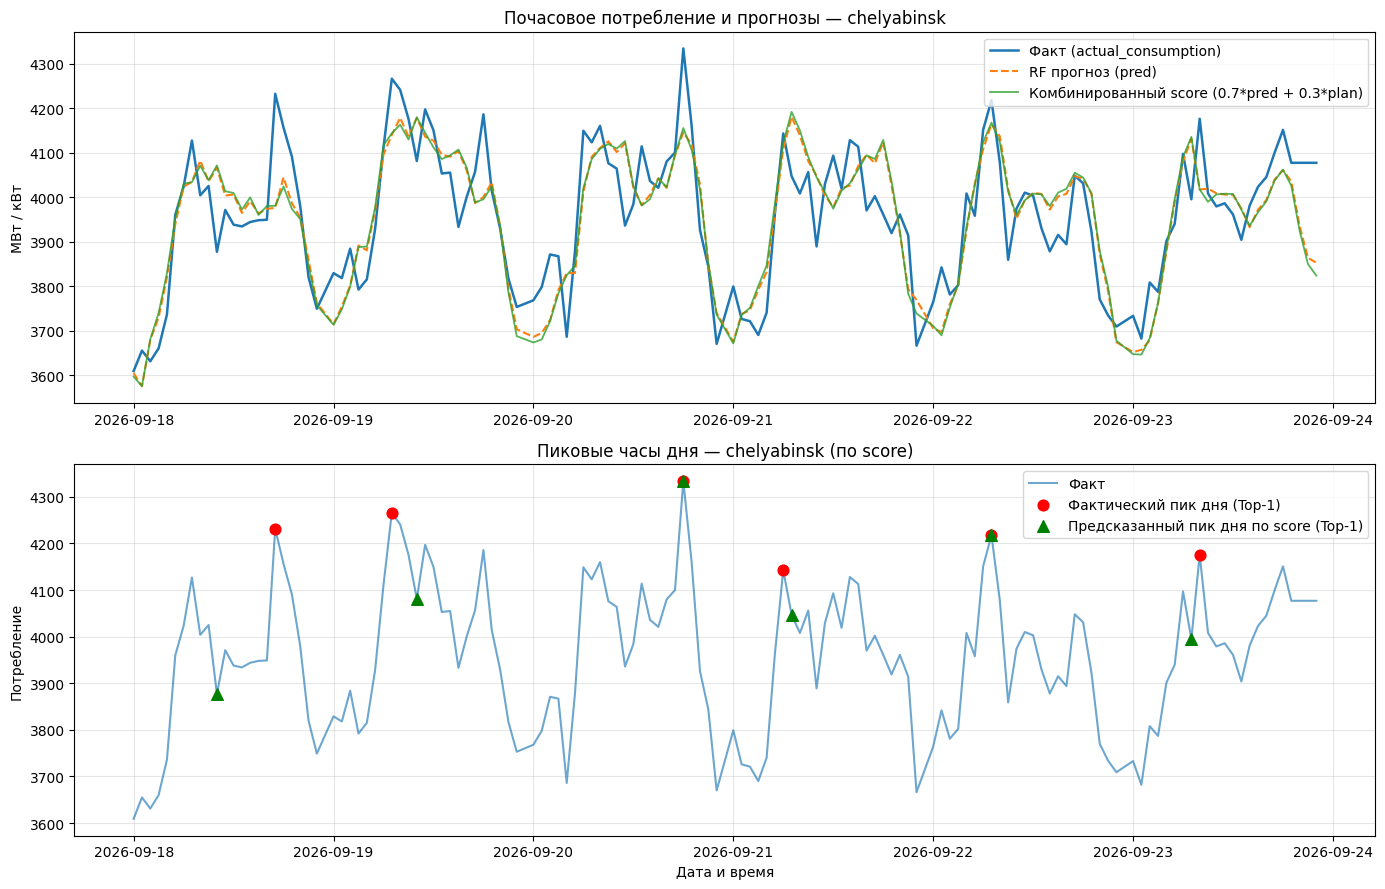

In [18]:
plot_region = 'chelyabinsk'  # 'chelyabinsk', 'kurgan' или 'tumen'
plot_col = 'score'  # 'score' или 'pred'

reg_df = test_df[test_df['region'] == plot_region].copy()
x_time = reg_df.index
tmp = reg_df.reset_index(drop=True)
tmp['dt'] = x_time

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=False)

axes[0].plot(
    tmp['dt'], tmp[target], label='Факт (actual_consumption)', linewidth=1.8
)
axes[0].plot(
    tmp['dt'],
    tmp['pred'],
    label='RF прогноз (pred)',
    linewidth=1.5,
    linestyle='--',
)
axes[0].plot(
    tmp['dt'],
    tmp['score'],
    label='Комбинированный score (0.7*pred + 0.3*plan)',
    linewidth=1.3,
    alpha=0.8,
)
axes[0].set_title(f'Почасовое потребление и прогнозы — {plot_region}')
axes[0].set_ylabel('МВт / кВт')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

true_peaks = tmp.groupby('date', group_keys=False).apply(
    lambda g: g.nlargest(1, target)
)
pred_peaks = tmp.groupby('date', group_keys=False).apply(
    lambda g: g.nlargest(1, plot_col)
)

axes[1].plot(tmp['dt'], tmp[target], label='Факт', color='tab:blue', alpha=0.65)
axes[1].scatter(
    true_peaks['dt'],
    true_peaks[target],
    color='red',
    s=60,
    zorder=5,
    label='Фактический пик дня (Top-1)',
)
axes[1].scatter(
    pred_peaks['dt'],
    pred_peaks[target],
    color='green',
    marker='^',
    s=70,
    zorder=6,
    label=f'Предсказанный пик дня по {plot_col} (Top-1)',
)
axes[1].set_title(f'Пиковые часы дня — {plot_region} (по {plot_col})')
axes[1].set_ylabel('Потребление')
axes[1].set_xlabel('Дата и время')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [14]:
#Важность признаков (опционально)
if last_model is not None:
  importances = pd.Series(
      last_model.feature_importances_, index=features
  ).sort_values(ascending=False)
  display(importances.round(4))

,0
lag_168,0.1449
lag_1,0.1380
planned_generation,0.1296
planned_consumption,0.1293
rolling_mean_24,0.1253
region_code,0.1170
lag_24,0.1073
actual_generation,0.0905
rolling_std_24,0.0181
hour,0.0000


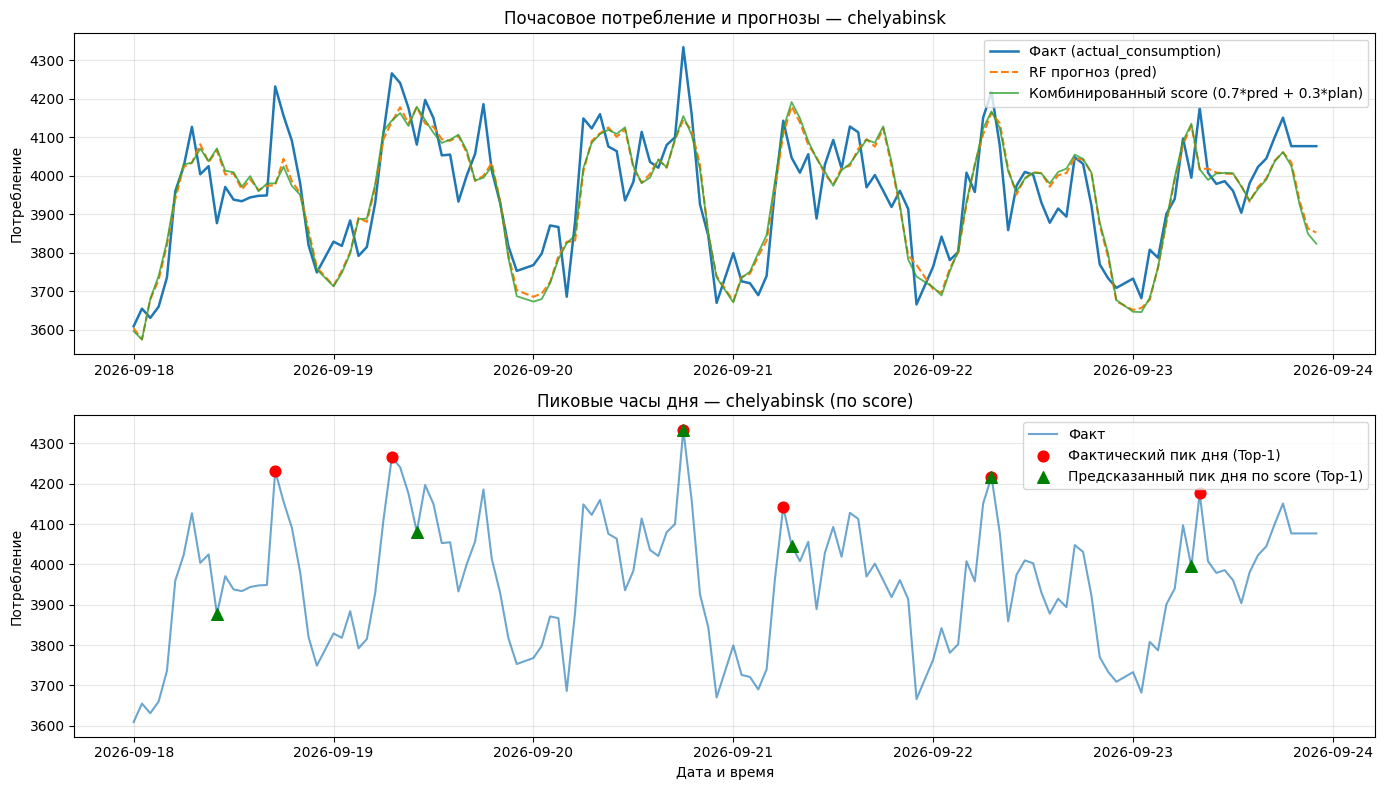

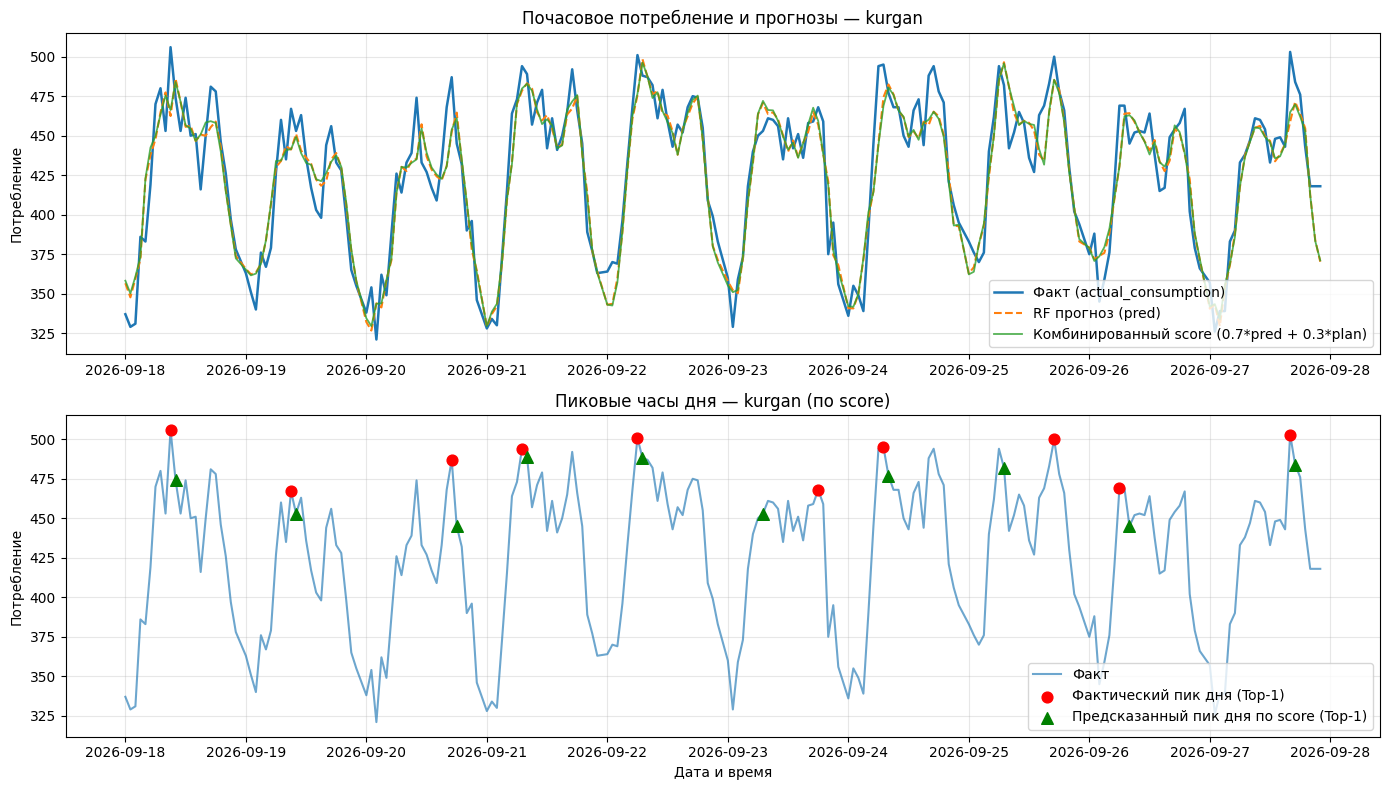

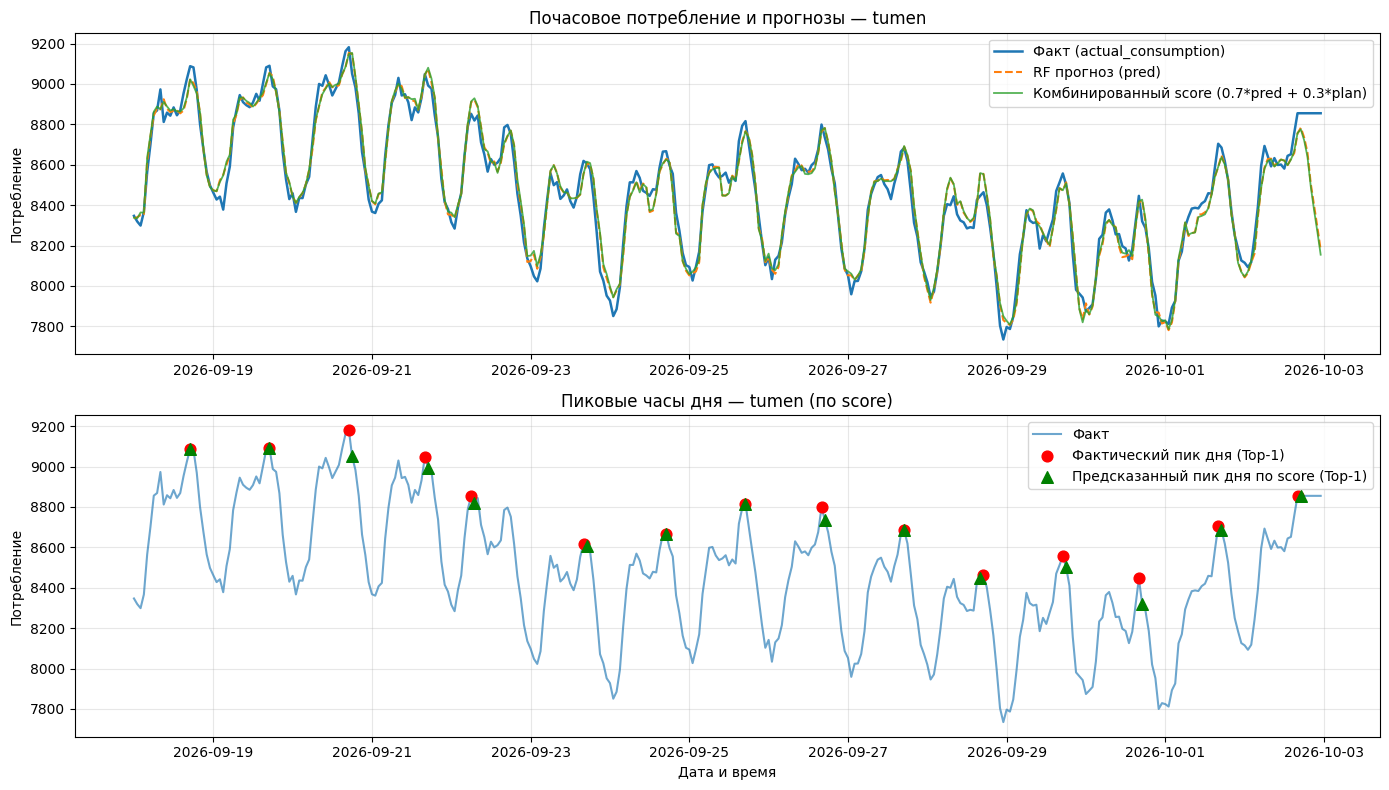

     region metric_col   MAE  RMSE     R2  Top-1_%  Top-3_%  Top-5_%  Hour_Diff
chelyabinsk       pred 70.94 88.70 0.6627     33.3     83.3    100.0       2.00
chelyabinsk      score 70.94 88.70 0.6627     33.3     66.7    100.0       2.00
     kurgan       pred 13.85 17.33 0.8614      0.0     80.0    100.0       3.00
     kurgan      score 13.85 17.33 0.8614      0.0     90.0    100.0       3.00
      tumen       pred 50.09 78.73 0.9374     40.0    100.0    100.0       0.60
      tumen      score 50.09 78.73 0.9374     33.3    100.0    100.0       0.67


In [20]:
plot_col = 'score'  # 'score' или 'pred'
rows = []


def get_daily_top1_rows(df_part: pd.DataFrame, value_col: str) -> pd.DataFrame:
  peak_indices = []
  for _, g in df_part.groupby('date', sort=False):
    peak_indices.append(g[value_col].idxmax())
  return df_part.loc[peak_indices]


for reg in sorted(test_df['region'].unique()):
  sub = test_df[test_df['region'] == reg].copy()
  if sub.empty:
    continue

  x_time = sub.index
  tmp = sub.reset_index(drop=True)
  tmp['dt'] = x_time

  mae_r = mean_absolute_error(tmp[target], tmp['pred'])
  rmse_r = np.sqrt(mean_squared_error(tmp[target], tmp['pred']))
  r2_r = r2_score(tmp[target], tmp['pred'])

  for col in ['pred', 'score']:
    res = evaluate_peak_hours(tmp, col)
    rows.append({
        'region': reg,
        'metric_col': col,
        'MAE': round(mae_r, 2),
        'RMSE': round(rmse_r, 2),
        'R2': round(r2_r, 4),
        'Top-1_%': round(res['Top-1'], 1),
        'Top-3_%': round(res['Top-3'], 1),
        'Top-5_%': round(res['Top-5'], 1),
        'Hour_Diff': round(res['Mean_Top1_Hour_Diff'], 2),
    })

  true_peaks = get_daily_top1_rows(tmp, target)
  pred_peaks = get_daily_top1_rows(tmp, plot_col)

  fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=False)

  axes[0].plot(
      tmp['dt'], tmp[target], label='Факт (actual_consumption)', linewidth=1.8
  )
  axes[0].plot(
      tmp['dt'],
      tmp['pred'],
      label='RF прогноз (pred)',
      linewidth=1.5,
      linestyle='--',
  )
  axes[0].plot(
      tmp['dt'],
      tmp['score'],
      label='Комбинированный score (0.7*pred + 0.3*plan)',
      linewidth=1.3,
      alpha=0.8,
  )
  axes[0].set_title(f'Почасовое потребление и прогнозы — {reg}')
  axes[0].set_ylabel('Потребление')
  axes[0].legend()
  axes[0].grid(True, alpha=0.3)

  axes[1].plot(
      tmp['dt'], tmp[target], label='Факт', color='tab:blue', alpha=0.65
  )
  axes[1].scatter(
      true_peaks['dt'],
      true_peaks[target],
      color='red',
      s=60,
      zorder=5,
      label='Фактический пик дня (Top-1)',
  )
  axes[1].scatter(
      pred_peaks['dt'],
      pred_peaks[target],
      color='green',
      marker='^',
      s=70,
      zorder=6,
      label=f'Предсказанный пик дня по {plot_col} (Top-1)',
  )
  axes[1].set_title(f'Пиковые часы дня — {reg} (по {plot_col})')
  axes[1].set_ylabel('Потребление')
  axes[1].set_xlabel('Дата и время')
  axes[1].legend()
  axes[1].grid(True, alpha=0.3)

  plt.tight_layout()
  plt.show()

summary_by_region = pd.DataFrame(rows)
print(summary_by_region.to_string(index=False))